# Fig. 1d-f: Behavior

[AI generated summary] Behavioral performance of the two monkeys:
- **Fig. 1d-e**: probability of choosing the high-payoff target and probability of switching across a block.
- **Fig. 1f**: logistic regression weights of the last 10 outcomes predicting a switch (two-sided permutation test, 1000 permutations, FDR-corrected across lags).

**How to run:** set `DATA_PATH` in `popy/config.py`, then run all cells. Uses `behavior/behavior_kapo.pkl`. The permutation test takes a few minutes. Figures are saved in `figs/`. Source data of the plotted panels are exported to `source_data/` (see `popy/source_data.py`).

---
# Setup

In [1]:
# imports

##% imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from popy.io_tools import load_behavior
from popy.behavior_data_tools import add_history_of_feedback, add_switch_info, drop_time_fields
from popy.behavioral_analysis import fit_glm
from popy.plotting.plotting_tools import plot_strategy, plot_glm_weights

In [2]:
import os
from popy.config import FIGS_PATH
os.makedirs(FIGS_PATH, exist_ok=True)  # the figure panels are saved here

---
# Load data

In [3]:
behav = load_behavior()
behav = drop_time_fields(behav)  # drop columns related to event timing
behav

,monkey,session,trial_id,block_id,best_target,target,feedback
0,ka,010720,0,0,2,3.0,1.0
1,ka,010720,1,0,2,3.0,0.0
2,ka,010720,2,0,2,1.0,1.0
3,ka,010720,3,0,2,1.0,0.0
4,ka,010720,4,0,2,3.0,1.0
...,...,...,...,...,...,...,...
39214,po,310822,419,9,2,1.0,0.0
39215,po,310822,420,9,2,1.0,1.0
39216,po,310822,421,9,2,1.0,1.0
39217,po,310822,422,9,2,1.0,1.0


---
# Create figures

## Fig. 1d-e, Performance and shifting curves

Monkey: ka, Model: recording, Percent best target selection: 0.77, Percent shift: 0.10
Monkey: po, Model: recording, Percent best target selection: 0.64, Percent shift: 0.22


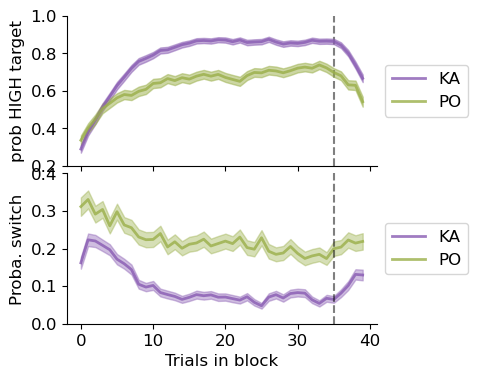

In [4]:
# plot strategy
fig, axs = plot_strategy(behav)
fig.savefig(os.path.join(FIGS_PATH, 'fig1de_strategy.svg'), dpi=300, bbox_inches='tight', transparent=True)

In [5]:
# Export source data (Figure 1d and Figure 1e)
from popy.source_data import export_source_data
from popy.plotting.plotting_tools import get_prop_event

# same computation as in plot_strategy(): each block (with >= 35 trials) is interpolated to 40 trials, then averaged across blocks
behav_sd = add_switch_info(behav)
behav_sd['if_best_target'] = behav_sd['target'] == behav_sd['best_target']
x_name = 'Trial in block (block length normalized to 40 trials)'
df_1d, df_1e = pd.DataFrame({x_name: np.arange(40)}), pd.DataFrame({x_name: np.arange(40)})
n_blocks = []
for monkey, behav_monkey in behav_sd.groupby('monkey'):
    for df_sd, column, y_name in [(df_1d, 'if_best_target', 'P(high-payoff target)'), (df_1e, 'switch', 'P(switch)')]:
        curves = get_prop_event(behav_monkey, column)[monkey]  # shape: (n blocks, 40)
        df_sd[f'{monkey.upper()} {y_name}, mean'] = curves.mean(axis=0)
        df_sd[f'{monkey.upper()} {y_name}, SEM'] = curves.std(axis=0) / np.sqrt(len(curves))
    block_lengths = behav_monkey.groupby(['session', 'block_id']).size()
    block_lengths = block_lengths[block_lengths >= 35]
    assert len(block_lengths) == len(curves)
    n_blocks.append(f'{monkey.upper()}: n = {len(curves)} blocks from {block_lengths.index.get_level_values("session").nunique()} sessions')
n_blocks = '; '.join(n_blocks)

for panel, df_sd, y_text in [('Figure 1d', df_1d, 'Probability of choosing the high-payoff target'), ('Figure 1e', df_1e, 'Probability of switching (choosing a different target than in the previous trial)')]:
    export_source_data(panel, df_sd,
                       f'{y_text} throughout a block, per monkey. Each block (blocks with at least 35 trials) is interpolated to 40 trials '
                       '(x as plotted, 0-39; the dashed line at x = 35 marks the start of the last five trials). '
                       f'Lines: mean across blocks; shading: mean ± SEM across blocks ({n_blocks}).')

Figure 1d: source data saved (40 rows)
Figure 1e: source data saved (40 rows)


## Fig. 1f, History dependence of switching

In [6]:
# add switch info and the outcomes of the last 10 trials
behav = load_behavior()
behav = drop_time_fields(behav)
behav = add_switch_info(behav, add_trials_since_switch=True)
behav = add_history_of_feedback(behav, one_column=False, num_trials=10)
behav = behav.dropna()
behav

,monkey,session,trial_id,block_id,best_target,target,feedback,switch,trials_since_switch,R_1,...,T_1,T_2,T_3,T_4,T_5,T_6,T_7,T_8,T_9,T_10
10,ka,010720,10,0,2,2.0,1.0,0.0,4,1.0,...,2.0,2.0,2.0,2.0,3.0,3.0,1.0,1.0,3.0,3.0
11,ka,010720,11,0,2,2.0,1.0,0.0,5,1.0,...,2.0,2.0,2.0,2.0,2.0,3.0,3.0,1.0,1.0,3.0
12,ka,010720,12,0,2,2.0,1.0,0.0,6,1.0,...,2.0,2.0,2.0,2.0,2.0,2.0,3.0,3.0,1.0,1.0
13,ka,010720,13,0,2,2.0,1.0,0.0,7,1.0,...,2.0,2.0,2.0,2.0,2.0,2.0,2.0,3.0,3.0,1.0
14,ka,010720,14,0,2,2.0,0.0,0.0,8,1.0,...,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,3.0,3.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
39214,po,310822,419,9,2,1.0,0.0,0.0,2,1.0,...,1.0,1.0,3.0,1.0,1.0,3.0,1.0,1.0,3.0,1.0
39215,po,310822,420,9,2,1.0,1.0,0.0,3,0.0,...,1.0,1.0,1.0,3.0,1.0,1.0,3.0,1.0,1.0,3.0
39216,po,310822,421,9,2,1.0,1.0,0.0,4,1.0,...,1.0,1.0,1.0,1.0,3.0,1.0,1.0,3.0,1.0,1.0
39217,po,310822,422,9,2,1.0,1.0,0.0,5,1.0,...,1.0,1.0,1.0,1.0,1.0,3.0,1.0,1.0,3.0,1.0


Permutation 1/1000 for monkey ka
Permutation 101/1000 for monkey ka
Permutation 201/1000 for monkey ka
Permutation 301/1000 for monkey ka
Permutation 401/1000 for monkey ka
Permutation 501/1000 for monkey ka
Permutation 601/1000 for monkey ka
Permutation 701/1000 for monkey ka
Permutation 801/1000 for monkey ka
Permutation 901/1000 for monkey ka
Monkey: ka, CV accuracy: 0.84 +/- 0.01
Permutation 1/1000 for monkey po
Permutation 101/1000 for monkey po
Permutation 201/1000 for monkey po
Permutation 301/1000 for monkey po
Permutation 401/1000 for monkey po
Permutation 501/1000 for monkey po
Permutation 601/1000 for monkey po
Permutation 701/1000 for monkey po
Permutation 801/1000 for monkey po
Permutation 901/1000 for monkey po
Monkey: po, CV accuracy: 0.77 +/- 0.03
Using p-value column: pvalue_fdr
Using p-value column: pvalue_fdr


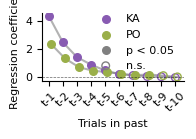

In [7]:
# Fit the GLM
monkeys = ['ka', 'po']
predictors = ['R_1', 'R_2', 'R_3', 'R_4', 'R_5', 'R_6', 'R_7', 'R_8', 'R_9', 'R_10']#, 'trials_since_switch', 'target', 'RT', 'best_target', 'trial_id']

behav_temp = behav[behav['monkey'].isin(monkeys)]
#behav_temp = behav_temp.loc[behav_temp['R_1'] == 1]  # remove the first 3 trials after a switch

df_res = fit_glm(behav_temp, target='switch', predictors=predictors, n_permutations=1000)

# Plot the results
saveas = os.path.join(FIGS_PATH, 'fig1f_glm_weights.svg')
plot_glm_weights(df_res,
                 fit_curve=False,
                 title=None, #f'GLM weights\nMonkey: Ka, ROC-AUC: {scores["ka"].mean():.2f}\nMonkey Po, ROC-AUC: {scores["po"].mean():.2f}',
                 saveas=saveas,
                 paper_format=True)

In [8]:
# Export source data (Figure 1f)
from popy.source_data import export_source_data

df_1f = pd.DataFrame({
    'Monkey': df_res['monkey'].str.upper(),
    'Trial in past': ['t-' + v.split('_')[1] for v in df_res['variable']],
    'Predictor': df_res['variable'],
    'Regression coefficient': df_res['coeffs'],
    'p-value (two-sided permutation test)': df_res['pvalue'],
    'p-value (FDR-corrected across lags)': df_res['pvalue_fdr'],
    'Significant (filled circle; FDR-corrected p < 0.05)': df_res['pvalue_fdr'] < 0.05,
})
n_trials = '; '.join(f'{m.upper()}: n = {n} trials' for m, n in behav_temp.groupby('monkey').size().items())
export_source_data('Figure 1f', df_1f,
                   'Weights of a logistic regression (class-balanced) predicting stay (1) vs. switch (0) in the current trial from the outcomes '
                   'of the past 10 trials (predictor R_k: trial t-k rewarded = 1, unrewarded = 0), fitted per monkey on all trials pooled across '
                   f'sessions ({n_trials}). p-values: two-sided permutation test (1000 permutations), Benjamini-Hochberg FDR-corrected across the 10 lags.')

Figure 1f: source data saved (20 rows)
